# 02.1 · Logistic regression: will a new Kindle book become popular?

**Project:** Digital Publishing Opportunity Intelligence

**Author:** Stefan Radević · Data Science Bootcamp · Capstone project

## 1. TL;DR

**Key findings**

- Logistic regression works clearly better than guessing: **ROC AUC 0.786** against 0.500 on **27,169 test books** from authors it has never seen.
- When it calls a book popular it is right **65.4%** of the time, and it finds **43.9%** of the popular books (accuracy **74.3%** against 67.6%).
- The **author's earlier books** are the strongest sign.
- Its weak spot is **first books**: it almost never predicts that one will be popular (recall 0.001).

## 2. Recap

**Question.** Can we predict, from the characteristics of a book draft, whether a new Kindle book will reach at least 100 ratings in
its first 12 months on Amazon?

**From the EDA (`01_eda.ipynb`).** The table has 135,839 books published from 2019 to 2021. A book is **popular** (`popular_first_year` = 1)
if it has at least 100 estimated ratings in its first 12 months. This is 32.4% of the books. Section 9.18 of the EDA shows how the
number was chosen.

**This notebook** trains one model and compares it with a simple baseline, following the course steps: split the data, tune on
the training books only, and look at the test books once at the end.

## 3. Setup

I load the libraries and the table from the EDA. `RANDOM_STATE` makes the split and the model the same every time.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score,
                             roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, StandardScaler

PROJECT = Path("..") if Path.cwd().name == "notebooks" else Path(".")
PROCESSED = PROJECT / "data" / "processed"
RANDOM_STATE = 42
TARGET = "popular_first_year"
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#c3c2b7"
pd.set_option("display.max_columns", 30, "display.width", 200, "display.max_colwidth", 50)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

books = pd.read_parquet(PROCESSED / "kindle_books_popularity.parquet")
print("Table:", books.shape)
print(f"Popular books: {books[TARGET].sum():,} ({books[TARGET].mean():.1%})")
books.head(3)

Table: (135839, 15)
Popular books: 44,036 (32.4%)


,parent_asin,title,author,niche,pages,title_words,is_series,self_published,author_earlier_books,publication_year,price,rating_number,first_year_reviews,first_year_ratings,popular_first_year
0,B07NDWT66X,51 Inspirational Sweet Western Romances Box Se...,Katie Wyatt,Religion & Spirituality,2845.0,18,1,0,215,2019,0.00,405,7.0,405.0,1
1,B08NRPBGGR,Back To You,Bates,Literature & Fiction,254.0,3,0,0,0,2021,6.99,38,3.0,28.5,0
2,B09L6VDZTF,The Senders of Fate: Warrior of the Dark Book 2,Garnet Hart,Literature & Fiction,312.0,10,1,1,4,2021,0.00,3,1.0,3.0,0


- The table has **135,839 books** and 15 columns.
- **44,036 books (32.4%)** are popular, so about one book in three is in the positive class.

## 4. Feature preparation

The model receives the characteristics of a draft and how it is published. Price, publication year, ratings, reviews and stars are
not used (`01_eda.ipynb`, section 11).

Logistic regression works with straight-line relations, and `author_earlier_books` is very skewed: most authors have few books and a few
have hundreds. So I use its logarithm, `log_earlier_books` (`np.log1p`, which also works for 0).

In [2]:
def prepare_features(data):
    data = data.copy()
    data["log_earlier_books"] = np.log1p(data["author_earlier_books"])
    return data


CONTINUOUS = ["pages", "title_words", "log_earlier_books"]
BINARY = ["is_series", "self_published"]
CATEGORICAL = ["niche"]
FEATURES = CONTINUOUS + BINARY + CATEGORICAL
books = prepare_features(books)
print("Features:", FEATURES)
books[FEATURES].isna().sum().to_frame("empty values").T

Features: ['pages', 'title_words', 'log_earlier_books', 'is_series', 'self_published', 'niche']


,pages,title_words,log_earlier_books,is_series,self_published,niche
empty values,6098,0,0,0,0,0


- The model gets **6 features**.
- Only `pages` has empty values (6,098 books), and the pipeline fills them with the median of the training books.

## 5. Train/test split

I keep **20% of the books for the final test**. All books of one author stay on the same side, so the test shows how the model works for
**authors it has not seen**. `StratifiedGroupKFold` does this and also keeps a similar share of popular books on both sides. It goes
one step beyond the plain `train_test_split` from the course, because a random split would put books by the same author on both sides.

In [3]:
groups = books["author"].fillna(books["parent_asin"])
X, y = books[FEATURES], books[TARGET]
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_index, test_index = next(splitter.split(X, y, groups))

X_train, X_test = X.iloc[train_index], X.iloc[test_index]
y_train, y_test = y.iloc[train_index], y.iloc[test_index]
groups_train, groups_test = groups.iloc[train_index], groups.iloc[test_index]
test_books = books.iloc[test_index].copy()

print(f"Training books: {len(X_train):,} ({y_train.mean():.1%} popular) | authors: {groups_train.nunique():,}")
print(f"Test books:     {len(X_test):,} ({y_test.mean():.1%} popular) | authors: {groups_test.nunique():,}")
print("Authors on both sides:", len(set(groups_train) & set(groups_test)))

Training books: 108,670 (32.4% popular) | authors: 64,046
Test books:     27,169 (32.4% popular) | authors: 16,017
Authors on both sides: 0


- **108,670 training books** and **27,169 test books**, each with **32.4%** popular books.
- **No author is on both sides** (0 shared authors), so the test really shows new authors.

## 6. Baseline

The baseline ignores the book and always predicts the most common answer. A model is useful only if it does better. The function
`measures` calculates the same numbers for every model.

In [4]:
def measures(name, true, probability, threshold=0.5):
    predicted = (probability >= threshold).astype(int)
    return {"model": name, "accuracy": accuracy_score(true, predicted),
            "precision": precision_score(true, predicted, zero_division=0), "recall": recall_score(true, predicted, zero_division=0),
            "f1": f1_score(true, predicted, zero_division=0), "roc_auc": roc_auc_score(true, probability)}


baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
baseline_probability = baseline.predict_proba(X_test)[:, 1]
pd.DataFrame([measures("baseline (test)", y_test, baseline_probability)]).set_index("model").round(3)

,accuracy,precision,recall,f1,roc_auc
model,,,,,
baseline (test),0.676,0.0,0.0,0.0,0.5


- The baseline always predicts "not popular". It is right for **67.6%** of the test books, but finds no popular book: precision, recall and F1 are **0**.
- Its ROC AUC is **0.5**, the same as guessing. A useful model must beat these numbers.

## 7. Candidate model

**Logistic regression** gives each feature a weight and turns the sum into a probability between 0 and 1.

- The **pipeline** fills empty `pages` with the median, scales the continuous features and turns `niche` into 0/1 columns, with
  *Literature & Fiction* as the reference niche. All of this is learned from training books only.
- `C` controls **regularization**: a small `C` keeps the weights small. `GridSearchCV` tries several values with 5 folds, keeps authors
  together in each fold, and chooses by ROC AUC.

In [5]:
preprocess = ColumnTransformer([
    ("continuous", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), CONTINUOUS),
    ("binary", "passthrough", BINARY),
    ("niche", OneHotEncoder(drop=[["Literature & Fiction"]], handle_unknown="ignore"), CATEGORICAL),
])
pipeline = Pipeline([("prepare", preprocess), ("model", LogisticRegression(max_iter=1000))])
grid = {"model__C": [0.01, 0.1, 1, 10]}

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
search = GridSearchCV(pipeline, grid, scoring="roc_auc", cv=cv, return_train_score=True)
search.fit(X_train, y_train, groups=groups_train)
best_model = search.best_estimator_

columns = [c for c in pd.DataFrame(search.cv_results_).columns if c.startswith("param_")]
results = pd.DataFrame(search.cv_results_)[columns + ["mean_train_score", "mean_test_score", "std_test_score", "rank_test_score"]]
results.columns = [c.replace("param_model__", "") for c in results.columns]
print("Best settings:", {k.replace("model__", ""): v for k, v in search.best_params_.items()})
print(f"Best validation ROC AUC: {search.best_score_:.4f}")
results.sort_values("rank_test_score").round(4)

Best settings: {'C': 0.1}
Best validation ROC AUC: 0.7739


,C,mean_train_score,mean_test_score,std_test_score,rank_test_score
1,0.10,0.7746,0.7739,0.0030,1
3,10.00,0.7746,0.7738,0.0031,2
2,1.00,0.7746,0.7738,0.0031,3
0,0.01,0.7740,0.7736,0.0026,4


- The best value is **C = 0.1**, with a validation ROC AUC of **0.7739**, but all four values give almost the same result (0.7736 to 0.7739).
- Training and validation are almost equal (0.7746 and 0.7739), so the model is **not overfitting**.

## 8. Evaluation

Now I use the **test books once**. I compare training and test results with the baseline. If the model were much better on training
books, it would be overfitting. I use a threshold of 0.5: a probability of 0.5 or more means "popular".

In [6]:
train_probability = best_model.predict_proba(X_train)[:, 1]
test_probability = best_model.predict_proba(X_test)[:, 1]
test_predicted = (test_probability >= 0.5).astype(int)
scores = pd.DataFrame([measures("baseline (test)", y_test, baseline_probability),
                       measures("Logistic regression (train)", y_train, train_probability),
                       measures("Logistic regression (test)", y_test, test_probability)]).set_index("model")
scores.round(3)

,accuracy,precision,recall,f1,roc_auc
model,,,,,
baseline (test),0.676,0.000,0.000,0.000,0.500
Logistic regression (train),0.731,0.624,0.427,0.507,0.775
Logistic regression (test),0.743,0.654,0.439,0.525,0.786


- The model beats the baseline: **accuracy 0.743** against 0.676 and **ROC AUC 0.786** against 0.500.
- **Precision 0.654:** about 2 of 3 books it calls popular really are.
- **Recall 0.439:** it finds fewer than half of the popular books.
- Training (0.775) and test (0.786) ROC AUC are close, so the result is stable.

The **confusion matrix** counts correct answers and the two kinds of errors. The **ROC curve** shows how well the model ranks books at every
threshold; the dashed line is guessing.

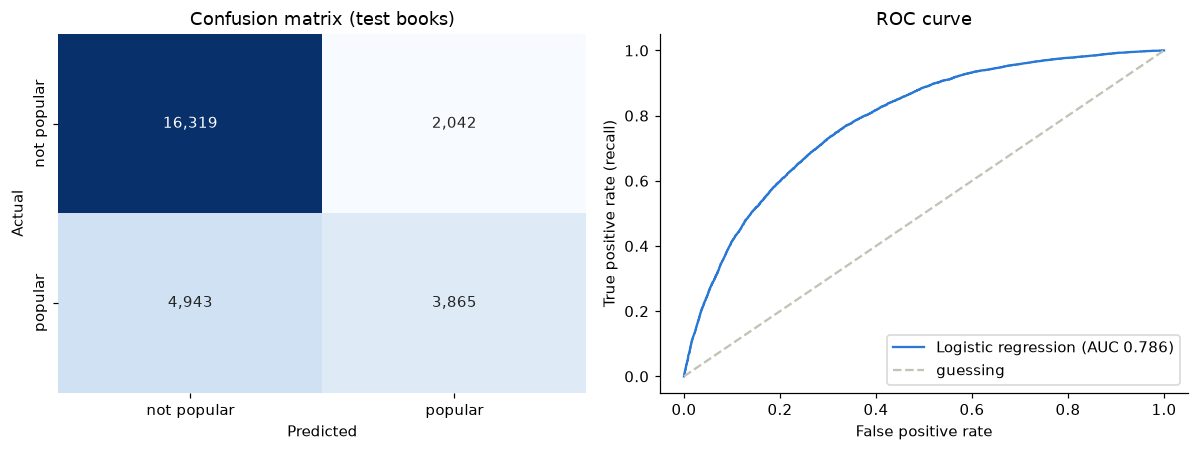

In [7]:
matrix = confusion_matrix(y_test, test_predicted)
fpr, tpr, _ = roc_curve(y_test, test_probability)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
sns.heatmap(matrix, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["not popular", "popular"], yticklabels=["not popular", "popular"])
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")
axes[0].set_title("Confusion matrix (test books)")
axes[1].plot(fpr, tpr, color=BLUE, label=f"Logistic regression (AUC {roc_auc_score(y_test, test_probability):.3f})")
axes[1].plot([0, 1], [0, 1], color=GREY, linestyle="--", label="guessing")
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate (recall)")
axes[1].set_title("ROC curve")
axes[1].legend()
plt.tight_layout()
plt.show()

- **Correct:** 16,319 books correctly called not popular and 3,865 correctly called popular.
- **False alarms:** 2,042 books were called popular but are not.
- **Missed:** 4,943 of the 8,808 popular books were not found. At 0.5 the model is careful.
- The ROC curve stays above the guessing line.

The **threshold** can be changed. A lower one finds more popular books but raises more false alarms. The second table checks whether the
probabilities can be read as chances: within each probability range I compare the average prediction with the real share of popular
books.

In [8]:
rows = []
for threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:
    row = measures(threshold, y_test, test_probability, threshold)
    row["books called popular"] = int((test_probability >= threshold).sum())
    rows.append(row)
threshold_table = pd.DataFrame(rows).rename(columns={"model": "threshold"}).set_index("threshold").drop(columns="roc_auc")

ranges = pd.cut(test_probability, np.linspace(0, 1, 11), include_lowest=True)
reliability = pd.DataFrame({"probability": test_probability, "actual": y_test.to_numpy()}).groupby(ranges, observed=True).agg(
    books=("actual", "size"), predicted_pct=("probability", lambda s: s.mean() * 100), actual_pct=("actual", lambda s: s.mean() * 100))
display(threshold_table.round(3))
reliability.round(1)

,accuracy,precision,recall,f1,books called popular
threshold,,,,,
0.3,0.703,0.530,0.750,0.621,12472
0.4,0.734,0.588,0.603,0.595,9025
0.5,0.743,0.654,0.439,0.525,5907
0.6,0.726,0.707,0.264,0.384,3287
0.7,0.704,0.746,0.130,0.222,1537


,books,predicted_pct,actual_pct
"(-0.001, 0.1]",3046,7.4,5.0
"(0.1, 0.2]",7130,14.6,11.9
"(0.2, 0.3]",4521,24.6,26.7
"(0.3, 0.4]",3447,34.8,37.6
"(0.4, 0.5]",3118,44.9,46.3
"(0.5, 0.6]",2620,54.9,58.9
"(0.6, 0.7]",1750,64.4,67.3
"(0.7, 0.8]",1065,74.4,73.8
"(0.8, 0.9]",399,84.2,75.9
"(0.9, 1.0]",73,93.2,78.1


- At **0.3** the model finds **75.0%** of the popular books, with a precision of 53.0%. At **0.7** it is right **74.6%** of the time, but finds only 13.0%.
- F1 is highest at 0.3 (0.621). I keep 0.5 so that all models are compared in the same way.
- The probabilities are close to the real shares up to 0.8. Above 0.8 the model is too sure: 84.2% predicted against 75.9% real, and 93.2% against 78.1%, in small groups.

## 9. Error analysis

Where does the model do well or badly? I compare groups of test books. `actual_%` is the real share of popular books and `predicted_%` is the
share the model calls popular.

In [9]:
test_books["probability"] = test_probability
test_books["predicted"] = test_predicted
test_books["route"] = np.where(test_books["self_published"] == 1, "self-published", "publisher")
test_books["experience"] = pd.cut(test_books["author_earlier_books"], [-1, 0, 2, 9, np.inf],
                                  labels=["first book", "1-2 earlier", "3-9 earlier", "10+ earlier"])


def group_report(column, minimum=300):
    rows = []
    for group, part in test_books.groupby(column, observed=True):
        if len(part) >= minimum and part[TARGET].nunique() == 2:
            rows.append({column: group, "books": len(part), "actual_%": part[TARGET].mean() * 100, "predicted_%": part["predicted"].mean() * 100,
                         "precision": precision_score(part[TARGET], part["predicted"], zero_division=0),
                         "recall": recall_score(part[TARGET], part["predicted"], zero_division=0),
                         "roc_auc": roc_auc_score(part[TARGET], part["probability"])})
    return pd.DataFrame(rows).set_index(column)


display(group_report("route").round(3))
display(group_report("experience").round(3))
niche_report = group_report("niche").sort_values("recall", ascending=False)
pd.concat([niche_report.head(4), niche_report.tail(4)]).round(3)

,books,actual_%,predicted_%,precision,recall,roc_auc
route,,,,,,
publisher,9991,46.912,40.687,0.654,0.568,0.706
self-published,17178,23.990,10.723,0.654,0.292,0.799


,books,actual_%,predicted_%,precision,recall,roc_auc
experience,,,,,,
first book,8411,13.042,0.083,0.143,0.001,0.734
1-2 earlier,4712,20.947,0.679,0.594,0.019,0.712
3-9 earlier,5729,32.798,11.189,0.527,0.180,0.665
10+ earlier,8317,58.254,62.847,0.671,0.724,0.656


,books,actual_%,predicted_%,precision,recall,roc_auc
niche,,,,,,
Romance,3112,47.943,44.087,0.652,0.600,0.704
"Mystery, Thriller & Suspense",1701,40.682,32.804,0.656,0.529,0.749
Religion & Spirituality,1641,39.488,29.921,0.646,0.489,0.766
Literature & Fiction,10025,35.641,26.035,0.667,0.488,0.781
Children's eBooks,1853,15.704,2.051,0.658,0.086,0.791
"Cookbooks, Food & Wine",340,24.118,4.412,0.267,0.049,0.682
"Health, Fitness & Dieting",362,22.099,0.829,0.667,0.025,0.777
Business & Money,988,12.449,0.506,0.400,0.016,0.731


- **Route:** recall is **0.292** for self-published books and **0.568** for publisher books, although the model ranks self-published books better (ROC AUC 0.799 against 0.706).
- **Experience:** for **first books** it calls only 0.083% popular, while 13.0% really are, so recall is **0.001**. For authors with 10+ earlier books recall is 0.724.
- **Niches:** recall is highest in **Romance** (0.600) and lowest among the shown niches in **Business & Money** (0.016).

I also look at the books where the model was most confident and wrong.

In [10]:
show = ["title", "niche", "pages", "is_series", "self_published", "author_earlier_books", "first_year_ratings", "probability"]
false_alarms = test_books[(test_books["predicted"] == 1) & (test_books[TARGET] == 0)].nlargest(5, "probability")[show]
missed = test_books[(test_books["predicted"] == 0) & (test_books[TARGET] == 1)].nsmallest(5, "probability")[show]
display(false_alarms.round(2))
display(missed.round(2))
print("Missed popular books:", f"{((test_books['predicted'] == 0) & (test_books[TARGET] == 1)).sum():,}",
      "| self-published:", f"{test_books.loc[(test_books['predicted'] == 0) & (test_books[TARGET] == 1), 'self_published'].mean():.1%}",
      "| median earlier books:", test_books.loc[(test_books['predicted'] == 0) & (test_books[TARGET] == 1), 'author_earlier_books'].median())

,title,niche,pages,is_series,self_published,author_earlier_books,first_year_ratings,probability
115721,The Collected Fiction of Robert E. Howard: Con...,Literature & Fiction,2623.0,0,0,86,0.00,0.99
22960,The History of England (Vol. 1-6): Illustrated...,History,2588.0,1,0,30,0.00,0.97
23146,The Complete Stories & Poems of Edgar Allan Poe,"Mystery, Thriller & Suspense",1605.0,0,0,148,11.00,0.95
126047,Las Vegas Paranormal Police Department: Ian De...,"Mystery, Thriller & Suspense",1507.0,1,0,31,46.89,0.94
96398,Ononokin Big Comedic Fantasy Box Set,Science Fiction & Fantasy,2113.0,0,0,40,59.00,0.93


,title,niche,pages,is_series,self_published,author_earlier_books,first_year_ratings,probability
20880,Hacking: The Unlocking of Transparency,Education & Teaching,144.0,0,1,0,183.00,0.04
117941,New York Notary Public: Prep Book with 3 Full ...,Education & Teaching,102.0,0,1,0,207.14,0.04
77414,Pentest Secrets: Breaking The Unbreakable Ente...,Computers & Technology,NaN,0,1,0,115.00,0.04
55398,Fire Stick: 2019 Ultimate User Guide to Unlock...,Computers & Technology,71.0,0,1,0,165.72,0.05
124378,Approaching (Almost) Any Machine Learning Problem,Education & Teaching,NaN,0,1,0,711.00,0.05


Missed popular books: 4,943 | self-published: 59.0% | median earlier books: 4.0


- **False alarms:** the most confident ones are very long collections (1,507 to 2,623 pages) from authors with 30 to 148 earlier books, with only 0 to 59 first-year ratings.
- **Missed books:** the most confident ones are self-published first books, mostly practical non-fiction, with 115 to 711 first-year ratings.
- Of the **4,943** missed popular books, **59.0%** are self-published, and their median author has 4 earlier books.

## 10. Interpretation

**Permutation importance** shuffles one feature in the test books and measures how much the ROC AUC falls. A large fall means the model relies
on that feature. I use 8,000 test books to keep this quick.

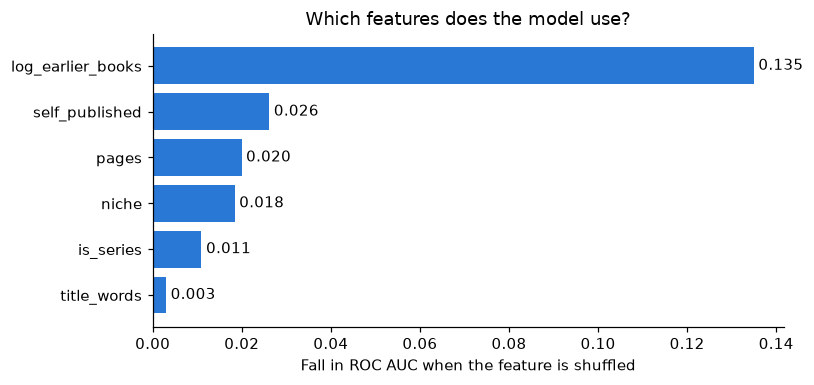

In [11]:
sample = X_test.sample(8000, random_state=RANDOM_STATE)
importance = permutation_importance(best_model, sample, y_test.loc[sample.index], scoring="roc_auc", n_repeats=5, random_state=RANDOM_STATE)
importance_table = pd.Series(importance.importances_mean, index=FEATURES, name="fall in ROC AUC").sort_values()

fig, ax = plt.subplots(figsize=(7.5, 3.6))
bars = ax.barh(importance_table.index, importance_table.values, color=BLUE)
ax.bar_label(bars, fmt="%.3f", padding=3)
ax.set_xlabel("Fall in ROC AUC when the feature is shuffled")
ax.set_title("Which features does the model use?")
plt.tight_layout()
plt.show()

- The model relies most on the **author's earlier books** (ROC AUC falls by **0.135**).
- Next come **self-published** (0.026), **pages** (0.020), **niche** (0.018) and **series** (0.011). **Title words** add very little (0.003).

The **odds ratio** shows how the odds of being popular change, with other features equal. Above 1 means higher odds and below 1 lower odds. For
scaled features it is the change for one standard deviation. For niches the comparison is with *Literature & Fiction*.

In [12]:
names = best_model.named_steps["prepare"].get_feature_names_out()
odds = pd.Series(np.exp(best_model.named_steps["model"].coef_[0]), index=names, name="odds ratio")
odds.index = odds.index.str.replace(r"^(continuous|binary|niche)__", "", regex=True).str.replace("niche_", "niche: ")
main = odds[~odds.index.str.startswith("niche:")].sort_values(ascending=False)
niche_odds = odds[odds.index.str.startswith("niche:")].sort_values(ascending=False)
display(main.round(3).to_frame())
pd.concat([niche_odds.head(4), niche_odds.tail(4)]).round(3).to_frame()

,odds ratio
log_earlier_books,2.040
is_series,1.539
pages,1.301
title_words,1.088
self_published,0.558


,odds ratio
niche: Humor & Entertainment,1.199
niche: Romance,1.065
niche: Religion & Spirituality,1.031
niche: LGBTQ+ eBooks,1.004
niche: Engineering & Transportation,0.470
niche: Reference,0.432
niche: Education & Teaching,0.337
niche: Computers & Technology,0.316


- **Author's earlier books:** **2.040**, so one standard deviation more about doubles the odds.
- **Series:** **1.539**, about 54% higher odds. **Pages:** 1.301 for one standard deviation more. **Title words:** 1.088.
- **Self-published:** **0.558**, about 44% lower odds than a publisher book.
- **Niches:** Humor & Entertainment (1.199) and Romance (1.065) are slightly above Literature & Fiction; **Computers & Technology** (0.316) and **Education & Teaching** (0.337) are far below.

Finally I give the model a few **invented book drafts** to see the estimated chance of reaching 100 ratings in the first year. All have 250 pages and
an 8-word title unless the description says otherwise.

In [13]:
examples = pd.DataFrame([
    ["Romance, self-published first book", "Romance", 250, 8, 0, 1, 0],
    ["Same book in a series", "Romance", 250, 8, 1, 1, 0],
    ["In a series, author has 10 earlier books", "Romance", 250, 8, 1, 1, 10],
    ["First book with a publisher", "Romance", 250, 8, 0, 0, 0],
    ["First book, 400 pages", "Romance", 400, 8, 0, 1, 0],
    ["Education, self-published first book", "Education & Teaching", 250, 8, 0, 1, 0],
], columns=["draft", "niche", "pages", "title_words", "is_series", "self_published", "author_earlier_books"])
examples["chance of 100+ ratings %"] = best_model.predict_proba(prepare_features(examples)[FEATURES])[:, 1] * 100
examples.drop(columns=["title_words"]).round(1)

,draft,niche,pages,is_series,self_published,author_earlier_books,chance of 100+ ratings %
0,"Romance, self-published first book",Romance,250,0,1,0,14.2
1,Same book in a series,Romance,250,1,1,0,20.3
2,"In a series, author has 10 earlier books",Romance,250,1,1,10,45.2
3,First book with a publisher,Romance,250,0,0,0,22.9
4,"First book, 400 pages",Romance,400,0,1,0,16.9
5,"Education, self-published first book",Education & Teaching,250,0,1,0,5.0


- A self-published first Romance book has an estimated chance of **14.2%**.
- In a series it is **20.3%**, and in a series by an author with 10 earlier books **45.2%**.
- With a publisher the first book has **22.9%**, and with 400 pages **16.9%**. The same first book in Education & Teaching has **5.0%**.
- These are **associations, not promises**.

## 11. Limitations & ethics

**Limitations**

- **The target is estimated.** First-year ratings come from dated reviews scaled to Amazon's total ratings, so books close to 100 can fall on the wrong side.
- **Ratings are not sales.** The model predicts reader response, not copies sold or income.
- **Only books with at least one review in the file are included**, so real chances for a new book are probably lower.
- `self_published` comes from my rule, and `author_earlier_books` counts only books in this catalog. Some "authors" are really companies.
- Marketing, cover, writing quality and reviews are not in the data.
- The model was built on books from 2019–2021, so it may not hold for later years.
- The results show **associations, not causes**.

**Ethics**

- The model favours experienced authors. It should not decide which authors or books deserve support.
- It is meant as **information for an author**. A low chance does not mean that a book is bad.

## 12. Conclusion

I save the test predictions and the main results for the comparison notebook.

In [14]:
output = test_books[["parent_asin", TARGET, "niche", "self_published", "author_earlier_books", "probability", "predicted"]]
output.to_parquet(PROCESSED / "predictions_popularity_logistic.parquet", index=False)
summary = {"model": "Logistic regression", "best_params": {k.replace("model__", ""): v for k, v in search.best_params_.items()},
           "cv_roc_auc": float(search.best_score_), "cv_std": float(search.cv_results_["std_test_score"][search.best_index_]),
           "train_roc_auc": float(roc_auc_score(y_train, train_probability)),
           "importance": {k: float(v) for k, v in importance_table.sort_values(ascending=False).items()}}
(PROCESSED / "results_popularity_logistic.json").write_text(json.dumps(summary, indent=2, default=str), encoding="utf-8")
print("Saved predictions:", output.shape)

Saved predictions: (27169, 7)


**What worked.** A simple and explainable model clearly beats the baseline (ROC AUC 0.786 against 0.500), does not overfit and works for authors it has not seen.

**What did not work.** It finds only 43.9% of the popular books and almost no popular first books.

**Next.** **02.2 Random forest** can use curved effects and combinations of features. It has to beat ROC AUC **0.786** on the same test books.